In [6]:
import networkx as nx
import numpy as np
import re
import math
import pandas as pd
import matplotlib.pyplot as plt
import random
from collections import Counter
from vem_sbm_new_version import VEM_SBM as VEM_SBM_NEW
from tqdm.auto import tqdm
from ILouvain_Gower import ML2Gower
from sklearn.metrics.cluster import adjusted_rand_score as ARI
from sa_cluster import sa_cluster
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score
from stoc import stoc
import pickle
col_dict = {0: 'red', 1: 'blue', 2: 'green', 3: 'orange', 4:'purple', 5:'black', 6:'yellow', 7:'pink', 8:'lightblue',9:'lime', 10:'sienna',11:'indigo'}

# First scenario

In [3]:
fits = {}
ilouvain_aris = []
sa_aris = []
stoc_aris = []

for sed in tqdm(range(500)):
    random.seed(sed)
    size_comm = [50,50,50]
    probs = [[0.6, 0.2, 0.05],[0.2,0.5,0.1],[0.05,0.1,0.5]]
    G=nx.stochastic_block_model(sizes=size_comm,p=probs,directed=False)

    Xg=np.zeros((150,2))
    Xg[:50,] = np.random.multivariate_normal(mean=[0.5, 0.5], cov=[[0.09, 0.001], [0.001, 0.09]], size=50)
    Xg[50:100,] = np.random.multivariate_normal(mean=[2.5, 2.5], cov=[[0.08, 0.002], [0.002, 0.09]], size=50)
    Xg[100:,] = np.random.multivariate_normal(mean=[-1.5, 2.5], cov=[[0.09, 0.003], [0.003, 0.08]], size=50)
    Xg=pd.DataFrame(Xg)
    A=nx.adjacency_matrix(G).todense()

    labels = []
    for n,i in enumerate(size_comm):
        labels += [n]*i

    Xc = pd.DataFrame(index=range(Xg.shape[0]), columns=['attr_cat1','attr_cat2'])
    Xc.loc[:49,'attr_cat1'] = random.choices([1,2,3], k=50, weights=[0.8,0.15,0.05])
    Xc.loc[50:99,'attr_cat1'] = random.choices([1,2,3], k=50, weights=[0.15,0.8,0.05])
    Xc.loc[100:,'attr_cat1'] = random.choices([1,2,3], k=50, weights=[0.05,0.15,0.8])

    Xc.loc[:49,'attr_cat2'] = random.choices([1,2,3,4], k=50, weights=[0.7,0.15,0.05,0.1])
    Xc.loc[50:99,'attr_cat2'] = random.choices([1,2,3,4], k=50, weights=[0.15,0.7,0.05,0.1])
    Xc.loc[100:,'attr_cat2'] = random.choices([1,2,3,4], k=50, weights=[0.05,0.15,0.7,0.1])

    fit = VEM_SBM_NEW(A, Xg=Xg, Xc=Xc, K=3, max_iter=50, tol=1e-8, verbose=False)
    fits[sed] = fit

    # ILOUVAIN
    attributes = {}
    for node in G.nodes():
        attributes[node] = {
            0: float(Xg.iloc[node, 0]),     # continuous
            1: float(Xg.iloc[node, 1]),     # continuous
            2: str(Xc.iloc[node, 0]),       # categorical
            3: str(Xc.iloc[node, 1]),       # categorical
        }

    attr_types = {0: 'continuous', 1: 'continuous',
                2: 'categorical', 3: 'categorical'}

    ml = ML2Gower(G, attributes, {n: n for n in G.nodes()}, attr_types)
    partition_ilouv = ml.findPartition()
    ilouvain_aris.append(ARI(list(partition_ilouv.values()), labels))

    # SA
    result_sa = sa_cluster(G, k=3, Xg=Xg, Xc=Xc, n_bins=10, 
                        l=20, c=0.15, sigma=0.5, verbose=False)
    sa_aris.append(adjusted_rand_score(labels, result_sa['labels']))

    # STOC
    result_stoc = stoc(G, Xg=Xg, Xc=Xc, tau=0.4, l=2)

    stoc_aris.append(ARI(labels, result_stoc['labels']))


with open('fits_scenario1.pkl', 'wb') as f:
    pickle.dump(fits, f)

with open('ilouv_aris_scenario1.pkl', 'wb') as f:
    pickle.dump(ilouvain_aris, f)

with open('sa_aris_scenario1.pkl', 'wb') as f:
    pickle.dump(sa_aris, f)

with open('stoc_aris_scenario1.pkl', 'wb') as f:
    pickle.dump(stoc_aris, f)

100%|██████████| 500/500 [36:44<00:00,  4.41s/it]


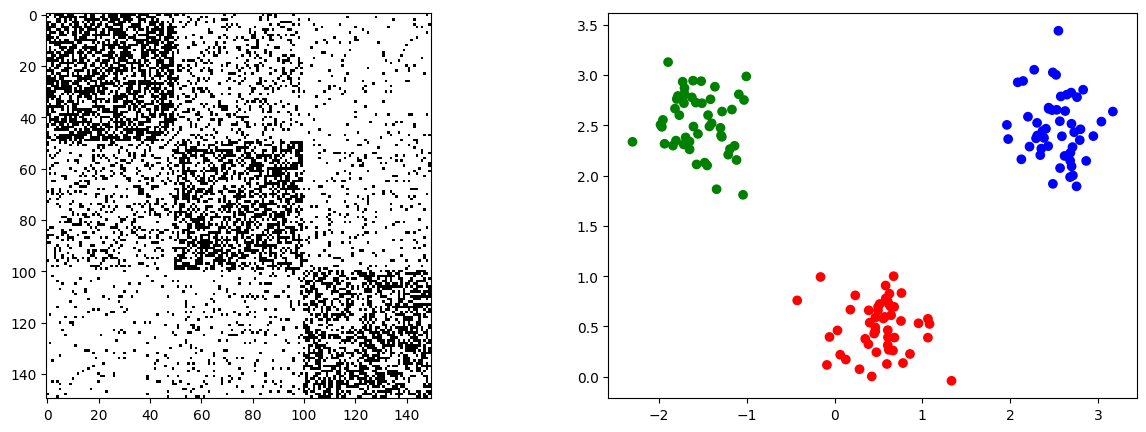

In [7]:
labels = []
for n,i in enumerate(size_comm):
    labels += [n]*i

A_bool = nx.to_numpy_array(G, dtype=bool)
dtemp = Xg.copy()
dtemp['label'] = labels
dtemp['label'] = dtemp['label'].map(col_dict)
fig, axs = plt.subplots(1,2,figsize=(15,5))
ax0 = axs.flatten()[0]
ax1 = axs.flatten()[1]
ax0.imshow(A_bool, cmap="Greys", interpolation="none")
ax1.scatter(dtemp.loc[:,0],dtemp.loc[:,1],c=dtemp['label'])
plt.show()

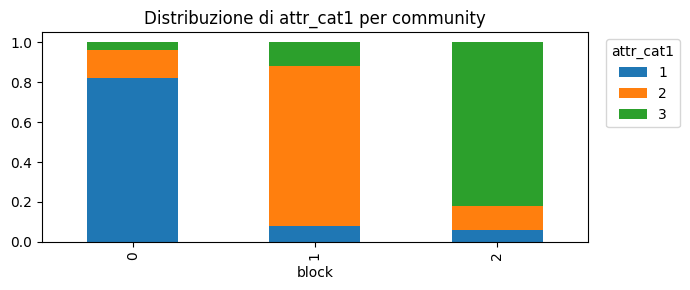

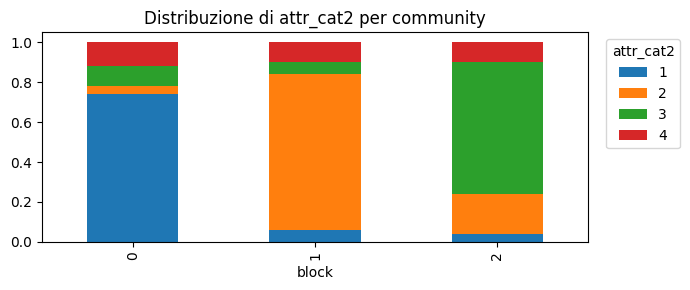

In [8]:
df = Xc.copy()
df["block"] = labels

for col in ["attr_cat1","attr_cat2"]:
    tab = pd.crosstab(df["block"], df[col], normalize="index")
    tab.plot(kind="bar", stacked=True, figsize=(7,3))
    plt.title(f"Distribuzione di {col} per community")
    plt.legend(title=col, bbox_to_anchor=(1.02,1), loc="upper left")
    plt.tight_layout()
    plt.show()

In [ ]:
#with open('Rs_results_EUregions.pkl', 'rb') as f:
#    Rs = pickle.load(f)

# Second scenario

In [9]:
fits = {}
ilouvain_aris = []
sa_aris = []
stoc_aris = []

for sed in tqdm(range(500)):
    random.seed(sed)
    size_comm = [50,50,50]
    probs = [[0.4, 0.2, 0.1],[0.2,0.4,0.2],[0.1,0.2,0.4]]
    G=nx.stochastic_block_model(sizes=size_comm,p=probs,directed=False)

    Xg=np.zeros((150,2))
    Xg[:50,] = np.random.multivariate_normal(mean=[0.5, 0.5], cov=[[0.09, 0.001], [0.001, 0.09]], size=50)
    Xg[50:100,] = np.random.multivariate_normal(mean=[2.5, 2.5], cov=[[0.08, 0.002], [0.002, 0.09]], size=50)
    Xg[100:,] = np.random.multivariate_normal(mean=[-1.5, 2.5], cov=[[0.09, 0.003], [0.003, 0.08]], size=50)
    Xg=pd.DataFrame(Xg)
    A=nx.adjacency_matrix(G).todense()

    labels = []
    for n,i in enumerate(size_comm):
        labels += [n]*i

    Xc = pd.DataFrame(index=range(Xg.shape[0]), columns=['attr_cat1','attr_cat2'])
    Xc.loc[:49,'attr_cat1'] = random.choices([1,2,3], k=50, weights=[0.8,0.15,0.05])
    Xc.loc[50:99,'attr_cat1'] = random.choices([1,2,3], k=50, weights=[0.15,0.8,0.05])
    Xc.loc[100:,'attr_cat1'] = random.choices([1,2,3], k=50, weights=[0.05,0.15,0.8])

    Xc.loc[:49,'attr_cat2'] = random.choices([1,2,3,4], k=50, weights=[0.7,0.15,0.05,0.1])
    Xc.loc[50:99,'attr_cat2'] = random.choices([1,2,3,4], k=50, weights=[0.15,0.7,0.05,0.1])
    Xc.loc[100:,'attr_cat2'] = random.choices([1,2,3,4], k=50, weights=[0.05,0.15,0.7,0.1])

    fit = VEM_SBM_NEW(A, Xg=Xg, Xc=Xc, K=3, max_iter=50, tol=1e-8, verbose=False)
    fits[sed] = fit

    # ILOUVAIN
    attributes = {}
    for node in G.nodes():
        attributes[node] = {
            0: float(Xg.iloc[node, 0]),     # continuous
            1: float(Xg.iloc[node, 1]),     # continuous
            2: str(Xc.iloc[node, 0]),       # categorical
            3: str(Xc.iloc[node, 1]),       # categorical
        }

    attr_types = {0: 'continuous', 1: 'continuous',
                2: 'categorical', 3: 'categorical'}

    ml = ML2Gower(G, attributes, {n: n for n in G.nodes()}, attr_types)
    partition_ilouv = ml.findPartition()
    ilouvain_aris.append(ARI(list(partition_ilouv.values()), labels))

    # SA
    result_sa = sa_cluster(G, k=3, Xg=Xg, Xc=Xc, n_bins=10, 
                        l=20, c=0.15, sigma=0.5, verbose=False)
    sa_aris.append(adjusted_rand_score(labels, result_sa['labels']))

    # STOC
    result_stoc = stoc(G, Xg=Xg, Xc=Xc, tau=0.4, l=2)

    stoc_aris.append(ARI(labels, result_stoc['labels']))


with open('fits_scenario2.pkl', 'wb') as f:
    pickle.dump(fits, f)

with open('ilouv_aris_scenario2.pkl', 'wb') as f:
    pickle.dump(ilouvain_aris, f)

with open('sa_aris_scenario2.pkl', 'wb') as f:
    pickle.dump(sa_aris, f)

with open('stoc_aris_scenario2.pkl', 'wb') as f:
    pickle.dump(stoc_aris, f)

100%|██████████| 500/500 [26:01<00:00,  3.12s/it]


# Third scenario

In [11]:
fits = {}
ilouvain_aris = []
sa_aris = []
stoc_aris = []

for sed in tqdm(range(500)):
    random.seed(sed)
    size_comm = [50,50,50]
    probs = [[0.6, 0.2, 0.05],[0.2,0.5,0.1],[0.05,0.1,0.5]]
    G=nx.stochastic_block_model(sizes=size_comm,p=probs,directed=False)

    Xg=np.zeros((150,2))
    Xg[:50,] = np.random.multivariate_normal(mean=[0, 0.5], cov=[[0.09, 0.001], [0.001, 0.09]], size=50)
    Xg[50:100,] = np.random.multivariate_normal(mean=[0.5, 0.5], cov=[[0.08, 0.002], [0.002, 0.09]], size=50)
    Xg[100:,] = np.random.multivariate_normal(mean=[1, 1], cov=[[0.09, 0.003], [0.003, 0.08]], size=50)
    Xg=pd.DataFrame(Xg)
    A=nx.adjacency_matrix(G).todense()

    labels = []
    for n,i in enumerate(size_comm):
        labels += [n]*i

    Xc = pd.DataFrame(index=range(Xg.shape[0]), columns=['attr_cat1','attr_cat2'])
    Xc.loc[:49,'attr_cat1'] = random.choices([1,2,3], k=50, weights=[0.33,0.33,0.34])
    Xc.loc[50:99,'attr_cat1'] = random.choices([1,2,3], k=50, weights=[0.35,0.5,0.15])
    Xc.loc[100:,'attr_cat1'] = random.choices([1,2,3], k=50, weights=[0.35,0.15,0.5])

    Xc.loc[:49,'attr_cat2'] = random.choices([1,2,3,4], k=50, weights=[0.25,0.25,0.25,0.25])
    Xc.loc[50:99,'attr_cat2'] = random.choices([1,2,3,4], k=50, weights=[0.25,0.6,0.05,0.1])
    Xc.loc[100:,'attr_cat2'] = random.choices([1,2,3,4], k=50, weights=[0.05,0.7,0.15,0.1])

    fit = VEM_SBM_NEW(A, Xg=Xg, Xc=Xc, K=3, max_iter=50, tol=1e-8, verbose=False)
    fits[sed] = fit

    # ILOUVAIN
    attributes = {}
    for node in G.nodes():
        attributes[node] = {
            0: float(Xg.iloc[node, 0]),     # continuous
            1: float(Xg.iloc[node, 1]),     # continuous
            2: str(Xc.iloc[node, 0]),       # categorical
            3: str(Xc.iloc[node, 1]),       # categorical
        }

    attr_types = {0: 'continuous', 1: 'continuous',
                2: 'categorical', 3: 'categorical'}

    ml = ML2Gower(G, attributes, {n: n for n in G.nodes()}, attr_types)
    partition_ilouv = ml.findPartition()
    ilouvain_aris.append(ARI(list(partition_ilouv.values()), labels))

    # SA
    result_sa = sa_cluster(G, k=3, Xg=Xg, Xc=Xc, n_bins=10, 
                        l=20, c=0.15, sigma=0.5, verbose=False)
    sa_aris.append(adjusted_rand_score(labels, result_sa['labels']))

    # STOC
    result_stoc = stoc(G, Xg=Xg, Xc=Xc, tau=0.4, l=2)

    stoc_aris.append(ARI(labels, result_stoc['labels']))


with open('fits_scenario3.pkl', 'wb') as f:
    pickle.dump(fits, f)

with open('ilouv_aris_scenario3.pkl', 'wb') as f:
    pickle.dump(ilouvain_aris, f)

with open('sa_aris_scenario3.pkl', 'wb') as f:
    pickle.dump(sa_aris, f)

with open('stoc_aris_scenario3.pkl', 'wb') as f:
    pickle.dump(stoc_aris, f)

100%|██████████| 500/500 [26:36<00:00,  3.19s/it]


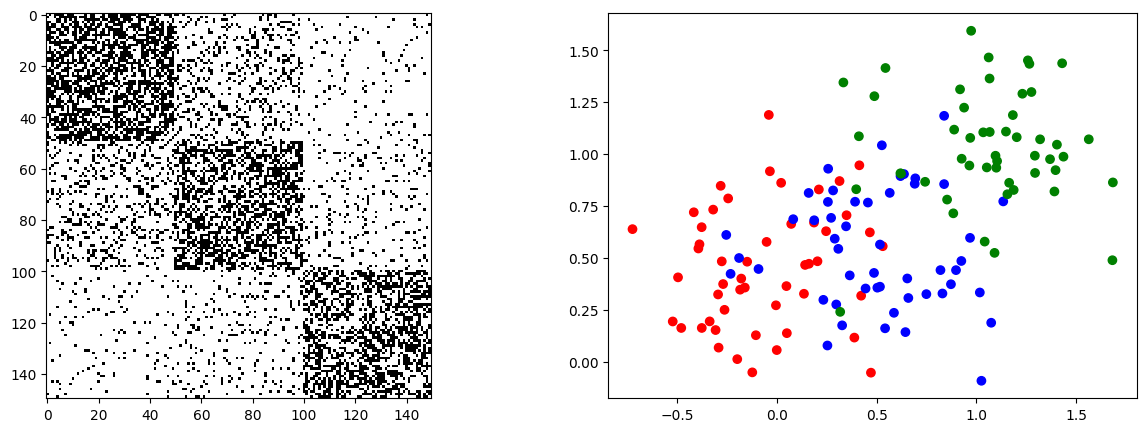

In [12]:
labels = []
for n,i in enumerate(size_comm):
    labels += [n]*i

A_bool = nx.to_numpy_array(G, dtype=bool)
dtemp = Xg.copy()
dtemp['label'] = labels
dtemp['label'] = dtemp['label'].map(col_dict)
fig, axs = plt.subplots(1,2,figsize=(15,5))
ax0 = axs.flatten()[0]
ax1 = axs.flatten()[1]
ax0.imshow(A_bool, cmap="Greys", interpolation="none")
ax1.scatter(dtemp.loc[:,0],dtemp.loc[:,1],c=dtemp['label'])
plt.show()